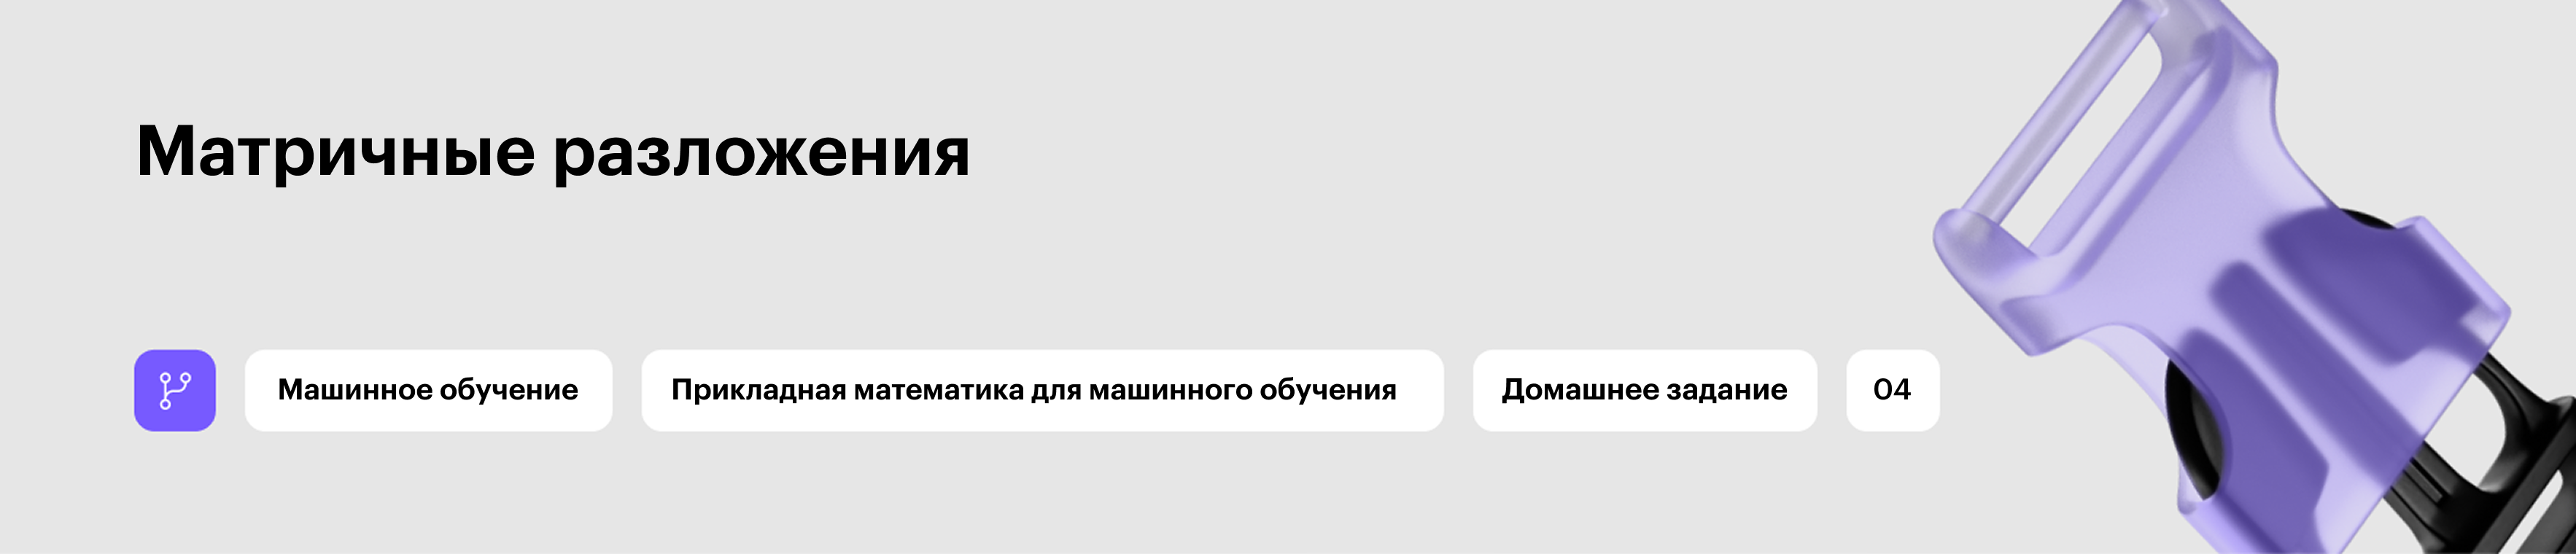

## Домашнее задание 4. Матричные разложения (2 балла)

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используй данный шаблон.</font>**

    ✅ Можно добавлять новые ячейки любых типов.
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий.


🔷 **<font color='plum'>При оценивании задач учитывается код.</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами «Your code here» / «Твой код» и аналогичными.
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов.
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно.

🔷 **<font color='plum'>При оценивании задач учитываются выводы.</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами «Вывод» / «Ответ на вопрос» / «Твой текст» и аналогичными.
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать Markdown, LaTeX).
    ✅ Сопутствующие изображения, графики, таблички приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## <font color='DarkOrange'> **Задание 1 [1 балл]**</font>

Используя SVD-разложение для матрицы $A$, определи:

a) <font color='DarkOrange'> **[0,1 балла]**</font> размерность $r$ матрицы $\Sigma$ для сокращённой записи SVD-разложения;

б) <font color='DarkOrange'> **[0,2 балла]**</font> $U_r, \Sigma_r, V_R^T$ сокращённой записи SVD-разложения;

в) <font color='DarkOrange'> **[0,7 баллa]**</font> наименьшее число сингулярных значений $k$, которые нужно оставить, чтобы по норме Фробениуса ошибка не превышала $0,5$:
$$||A - A_k||_F = \sqrt{\sum_{i=k+1}^{r} \sigma_i^2}.$$


<font color='MediumTurquoise'>**Tip:**</font>
`numpy.linalg.svd`, `np.diag`, $A = U_r\Sigma_rV_r^T, r = rg(A)$, $\ A \approx U_k\Sigma_kV_k^T, k \le r $.

In [ ]:
import numpy as np

In [ ]:
rng = np.random.default_rng(1337)
A = rng.random((7,8))
A[3,:] = A[4,:] + A[6,:]

In [ ]:
A

array([[0.8781019 , 0.18552796, 0.92090045, 0.94656586, 0.87450809,
        0.11574276, 0.19373166, 0.3417372 ],
       [0.4957909 , 0.89837123, 0.00645862, 0.22741147, 0.79365495,
        0.41428672, 0.0838144 , 0.39209564],
       [0.33957123, 0.02230247, 0.89043832, 0.02386968, 0.83582032,
        0.45959842, 0.04043169, 0.8129903 ],
       [1.78118683, 1.20358689, 1.83281565, 1.70255226, 0.41540976,
        0.43138606, 0.33967463, 0.76732989],
       [0.9736314 , 0.74049131, 0.97876734, 0.78617146, 0.13355676,
        0.11939021, 0.22190831, 0.62590105],
       [0.70065334, 0.76965135, 0.40521232, 0.35101261, 0.90121237,
        0.09213922, 0.20520238, 0.32427928],
       [0.80755543, 0.46309558, 0.85404831, 0.9163808 , 0.28185301,
        0.31199585, 0.11776632, 0.14142884]])

In [17]:
r = np.linalg.matrix_rank(A)
print("Ранг A:", r)
print("Размер Sigma_r:", (r, r))


U, s, Vt = np.linalg.svd(A, full_matrices=False)

U_r = U[:, :r]
Sigma_r = np.diag(s[:r])
Vt_r = Vt[:r, :]

print("U_r:\n", U_r)

print("Sigma_r:\n", Sigma_r)
print("V_rᵀ:\n", Vt_r)

for k in range(r + 1):
    error = np.sqrt(np.sum(s[k:r] ** 2))
    print(f"k = {k}, ошибка = {error:.4f}")

    if error <= 0.5:
        break

print("Минимальное число сингулярных значений:", k)

Ранг A: 3
Размер Sigma_r: (np.int64(3), np.int64(3))
U_r:
 [[-0.79046554  0.02818728  0.61185758]
 [-0.52954661 -0.53345273 -0.6595518 ]
 [ 0.30780613 -0.84536008  0.43660248]]
Sigma_r:
 [[5.72923331 0.         0.        ]
 [0.         3.85976479 0.        ]
 [0.         0.         1.13053148]]
V_rᵀ:
 [[-0.79046554 -0.30780613  0.52954661]
 [-0.02818728 -0.84536008 -0.53345273]
 [ 0.61185758 -0.43660248  0.6595518 ]]
k = 0, ошибка = 7.0000
k = 1, ошибка = 4.0219
k = 2, ошибка = 1.1305
k = 3, ошибка = 0.0000
Минимальное число сингулярных значений: 3


## <font color='DarkOrange'> **Задание 2 [0,7 балла]**</font>

Используя SVD-разложение, сократи размерность признаков матрицы $A$ до 2. Изобрази на графике значения оставшихся признаков у объектов.

<font color='MediumTurquoise'>**Tip:**</font>
 `matplotlib.pyplot.scatter`.


In [19]:
rng = np.random.default_rng(2025)
A = rng.random((200,8))

In [20]:
A

array([[0.99445781, 0.38200974, 0.82714801, ..., 0.07722503, 0.31745641,
        0.91955541],
       [0.67586956, 0.28582494, 0.38954302, ..., 0.15343643, 0.9740917 ,
        0.42389585],
       [0.06314389, 0.49158648, 0.28834337, ..., 0.57902053, 0.59085026,
        0.88806449],
       ...,
       [0.34176001, 0.78561309, 0.70108401, ..., 0.97095733, 0.60752729,
        0.31605727],
       [0.15945474, 0.78216987, 0.34247698, ..., 0.56127705, 0.94858573,
        0.51078904],
       [0.69577242, 0.82542894, 0.72576606, ..., 0.26591927, 0.85517412,
        0.94190334]])

Размер после сокращения: (200, 2)


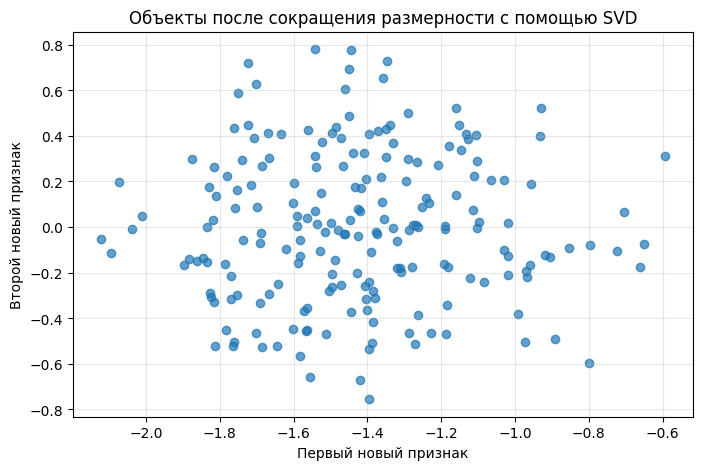

In [ ]:
# Your code here
U, s, Vt = np.linalg.svd(A, full_matrices=False)


A_2 = A @ Vt[:2, :].T

print("Размер после сокращения:", A_2.shape)

plt.figure(figsize=(8, 5))
plt.scatter(A_2[:, 0], A_2[:, 1], alpha=0.7)
plt.xlabel("Первый новый признак")
plt.ylabel("Второй новый признак")
plt.title("Объекты после сокращения размерности с помощью SVD")
plt.grid(alpha=0.3)

## <font color='DarkOrange'> **Задание 3 [0,3 балла]**</font>

Выполни QR-разложение матрицы $A$. Убедись, что $Q$ — ортогональная матрица.

<font color='MediumTurquoise'>**Tip:**</font>
`numpy.linalg.qr`.


In [22]:
A = np.array([[4, 1, -2],
              [2, 3, -1],
              [-1, 2, 3]])

In [23]:
# Your code here
Q, R = np.linalg.qr(A)
print("Q:\n", Q)
print("R:\n", R)

print("QR совпадает с A:", np.allclose(Q @ R, A))

Q:
 [[-0.87287156  0.15827748  0.46156633]
 [-0.43643578 -0.67627649 -0.59344243]
 [ 0.21821789 -0.71944308  0.65938047]]
R:
 [[-4.58257569 -1.74574312  2.83683257]
 [ 0.         -3.30943816 -1.7986077 ]
 [ 0.          0.          1.64845118]]
QR совпадает с A: True
